# ResNet50 vs MobileNetV2 vs Hybrid (MobileNetV2 + ResNet50) — with Grad-CAM & Grad-CAM++

## 1. Imports and environment

In [1]:
import os

# These are read by TensorFlow when it initializes (set them before importing TensorFlow).
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["TF_CUDNN_DETERMINISTIC"] = "1"

import json
import platform
import random
import time
from datetime import datetime
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
)

print("Python:", platform.python_version())
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)

build_info = tf.sysconfig.get_build_info()
print("CUDA in TensorFlow build:", build_info.get("cuda_version", "not available"))
print("cuDNN in TensorFlow build:", build_info.get("cudnn_version", "not available"))

gpu_devices = tf.config.list_physical_devices("GPU")
print("GPU available:", bool(gpu_devices))
print("GPU devices:", gpu_devices if gpu_devices else "None; training will use the CPU")

Python: 3.13.16
TensorFlow: 2.21.0
NumPy: 2.1.3
pandas: 2.3.3
scikit-learn: 1.6.1
Matplotlib: 3.10.0
CUDA in TensorFlow build: 12.5.1
cuDNN in TensorFlow build: 9
GPU available: True
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Hyperparameters and reproducibility
These values are shared by all three models (unchanged from the reference notebook).

In [2]:
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 30
LEARNING_RATE = 0.001
DROPOUT_RATE = 0.3
EARLY_STOPPING_PATIENCE = 7
NUM_PARALLEL_CALLS = tf.data.AUTOTUNE

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

print("Random seeds set to", SEED)
print("Deterministic TensorFlow operations enabled where supported.")

Random seeds set to 42
Deterministic TensorFlow operations enabled where supported.


## 3. Paths and output folders

In [3]:
# Kaggle dataset source directory (change this if you run the notebook somewhere else)
DATASET_ROOT = Path("/kaggle/input/datasets/miranibrahim/lung-cancer-mendely-dataset/Lung_Cancer_Augmented_Dataset_V4")

TRAIN_DIR = DATASET_ROOT / "train"
VAL_DIR = DATASET_ROOT / "valid"
TEST_DIR = DATASET_ROOT / "test"

# Kaggle output directory (persistent when the notebook version is saved)
RESULTS_ROOT = Path("/kaggle/working/Lung_Cancer_Classification_Results")

# Each run gets a new timestamped folder so previous results are not overwritten.
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_DIR = RESULTS_ROOT / f"run_{RUN_ID}"

MODELS_DIR = RUN_DIR / "models"
HISTORIES_DIR = RUN_DIR / "histories"
METRICS_DIR = RUN_DIR / "metrics"
GRAPHS_DIR = RUN_DIR / "graphs"
PREDICTIONS_DIR = RUN_DIR / "predictions"
CHECKPOINTS_DIR = RUN_DIR / "checkpoints"
CONFIG_DIR = RUN_DIR / "experiment_config"
XAI_DIR = RUN_DIR / "xai"

for output_dir in (MODELS_DIR, HISTORIES_DIR, METRICS_DIR, GRAPHS_DIR,
                   PREDICTIONS_DIR, CHECKPOINTS_DIR, CONFIG_DIR, XAI_DIR):
    output_dir.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATASET_ROOT)
print("Results for this run will be saved in:", RUN_DIR)

# Verify dataset directories
assert TRAIN_DIR.exists(), f"Training directory not found: {TRAIN_DIR}"
assert VAL_DIR.exists(), f"Validation directory not found: {VAL_DIR}"
assert TEST_DIR.exists(), f"Test directory not found: {TEST_DIR}"
print("Dataset directories verified successfully!")

Dataset: /kaggle/input/datasets/miranibrahim/lung-cancer-mendely-dataset/Lung_Cancer_Augmented_Dataset_V4
Results for this run will be saved in: /kaggle/working/Lung_Cancer_Classification_Results/run_20261127_111117
Dataset directories verified successfully!


## 4. Dataset: classes, counts and loading
The same `train` / `valid` / `test` folders are used for every model.

In [4]:
def get_class_directories(split_dir):
    return sorted(path.name for path in split_dir.iterdir() if path.is_dir())

class_names = get_class_directories(TRAIN_DIR)
if len(class_names) < 2:
    raise ValueError(f"Expected at least two class folders, found: {class_names}")

for split_name, split_dir in (("validation", VAL_DIR), ("test", TEST_DIR)):
    split_classes = get_class_directories(split_dir)
    if split_classes != class_names:
        raise ValueError(
            f"Class folders differ in {split_name}: expected {class_names}, found {split_classes}"
        )

NUM_CLASSES = len(class_names)
class_indices = np.arange(NUM_CLASSES)
print("Class names (folder order):", class_names)
print("Number of classes:", NUM_CLASSES)

SUPPORTED_IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}

def count_images_by_class(split_dir):
    counts = {}
    for class_name in class_names:
        class_dir = split_dir / class_name
        counts[class_name] = sum(
            1
            for path in class_dir.rglob("*")
            if path.is_file() and path.suffix.lower() in SUPPORTED_IMAGE_SUFFIXES
        )
    return counts

split_counts = {
    "train": count_images_by_class(TRAIN_DIR),
    "validation": count_images_by_class(VAL_DIR),
    "test": count_images_by_class(TEST_DIR),
}
counts_df = pd.DataFrame(split_counts).reindex(class_names)
counts_df.loc["TOTAL"] = counts_df.sum(axis=0)
display(counts_df)

if any(count == 0 for split in split_counts.values() for count in split.values()):
    raise ValueError("At least one class has no supported images in a split; inspect the folders.")

Class names (folder order): ['Benign', 'Malignant', 'Normal']
Number of classes: 3


,train,validation,test
Benign,735,70,71
Malignant,751,157,158
Normal,735,62,63
TOTAL,2221,289,292


In [5]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED,
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False,
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False,
)

if train_ds.class_names != class_names or val_ds.class_names != class_names or test_ds.class_names != class_names:
    raise ValueError("TensorFlow loaded different class orders across the data splits.")

# Keep the test file paths (same order as the test labels, since shuffle=False).
# They are needed later to load the exact same images for Grad-CAM / Grad-CAM++.
test_file_paths = list(test_ds.file_paths)

data_options = tf.data.Options()
data_options.experimental_deterministic = True
train_ds = train_ds.with_options(data_options).prefetch(NUM_PARALLEL_CALLS)
val_ds = val_ds.with_options(data_options).prefetch(NUM_PARALLEL_CALLS)
test_ds = test_ds.with_options(data_options).prefetch(NUM_PARALLEL_CALLS)

print("Loaded samples:", {name: sum(values.values()) for name, values in split_counts.items()})

Found 2221 files belonging to 3 classes.
Found 289 files belonging to 3 classes.
Found 292 files belonging to 3 classes.
Loaded samples: {'train': 2221, 'validation': 289, 'test': 292}


## 5. Model definitions
Architectures are identical to the reference notebook. The only change is that the unused models (DenseNet121, EfficientNetB0, Swin)
and the optional `HIDDEN_UNITS` switch (it was `0`, i.e. disabled) were removed.

In [6]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2, ResNet50
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

# Backbone constructor + its matching preprocessing function
MODEL_CONFIGS = {
    "ResNet50": (ResNet50, resnet_preprocess),
    "MobileNetV2": (MobileNetV2, mobilenet_preprocess),
}

# Hybrid model name -> the backbones that are fused
HYBRID_CONFIGS = {
    "Hybrid_MobileNetV2_ResNet50": ("MobileNetV2", "ResNet50"),
}

BASELINE_MODELS = list(MODEL_CONFIGS)
MODEL_NAMES = BASELINE_MODELS + list(HYBRID_CONFIGS)   # fixed order used in every table / plot

def get_branches(model_name):
    # Which backbone(s) a model uses (a baseline model has exactly one).
    return HYBRID_CONFIGS.get(model_name, (model_name,))

def compile_model(model):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

def build_model(model_name):
    # Baseline: frozen backbone -> GAP -> Dropout -> Dense(softmax)
    backbone_constructor, preprocess_function = MODEL_CONFIGS[model_name]
    backbone = backbone_constructor(
        weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3)
    )
    backbone.trainable = False

    inputs = layers.Input(shape=(*IMG_SIZE, 3), name="image")
    x = layers.Lambda(preprocess_function, name=f"{model_name}_preprocessing")(inputs)
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = layers.Dropout(DROPOUT_RATE, name="classifier_dropout")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="class_probabilities")(x)

    return compile_model(models.Model(inputs, outputs, name=f"{model_name}_classifier"))

def build_hybrid_model(hybrid_name, branch_names):
    # Hybrid: one frozen backbone per branch -> GAP each -> Concatenate -> Dropout -> Dense(softmax)
    inputs = layers.Input(shape=(*IMG_SIZE, 3), name="image")
    branch_features = []
    for branch in branch_names:
        backbone_constructor, preprocess_function = MODEL_CONFIGS[branch]
        backbone = backbone_constructor(
            weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3)
        )
        backbone.trainable = False
        x = layers.Lambda(preprocess_function, name=f"{branch}_preprocessing")(inputs)
        x = backbone(x, training=False)
        x = layers.GlobalAveragePooling2D(name=f"{branch}_gap")(x)
        branch_features.append(x)

    x = layers.Concatenate(name="feature_fusion")(branch_features)
    x = layers.Dropout(DROPOUT_RATE, name="fusion_dropout")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="class_probabilities")(x)

    return compile_model(models.Model(inputs, outputs, name=hybrid_name))

def build_any_model(model_name):
    if model_name in HYBRID_CONFIGS:
        return build_hybrid_model(model_name, HYBRID_CONFIGS[model_name])
    return build_model(model_name)

print("Models to train:", MODEL_NAMES)

Models to train: ['ResNet50', 'MobileNetV2', 'Hybrid_MobileNetV2_ResNet50']


## 6. Train all three models
Same seed, data, optimizer, callbacks and epochs for every model. The best (lowest validation loss) weights are restored.

In [7]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

trained_models = {}
trained_histories = {}
training_seconds = {}

for model_name in MODEL_NAMES:
    print("\n" + "=" * 60)
    print("Building and training:", model_name)
    print("=" * 60)

    # Reset state and seed so every model starts under identical conditions.
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_any_model(model_name)
    model.summary()

    checkpoint_path = CHECKPOINTS_DIR / f"{model_name}_best.weights.h5"
    callbacks = [
        EarlyStopping(monitor="val_loss", patience=EARLY_STOPPING_PATIENCE,
                      restore_best_weights=True, verbose=1),
        ModelCheckpoint(filepath=str(checkpoint_path), monitor="val_loss",
                        save_best_only=True, save_weights_only=True, verbose=1),
    ]

    fit_started = time.perf_counter()
    history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                        callbacks=callbacks, verbose=1)
    training_seconds[model_name] = time.perf_counter() - fit_started

    # Explicitly restore the minimum-validation-loss checkpoint before evaluation.
    model.load_weights(str(checkpoint_path))
    trained_models[model_name] = model
    trained_histories[model_name] = history

    weights_path = MODELS_DIR / f"{model_name}_best.weights.h5"
    model.save_weights(str(weights_path))
    print(f"Fit time: {training_seconds[model_name] / 60:.2f} minutes")
    print("Best weights saved:", weights_path)


Building and training: ResNet50
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "ResNet50_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ResNet50_preprocessing (Lambda) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 3)              │         6,147 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,593,859 (90.00 MB)

 Trainable params: 6,147 (24.01 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

... (9 outputs left out)

 Total params: 25,855,683 (98.63 MB)

 Trainable params: 9,987 (39.01 KB)

 Non-trainable params: 25,845,696 (98.59 MB)

Epoch 1/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.7356 - loss: 0.6557
Epoch 1: val_loss improved from None to 0.24241, saving model to /kaggle/working/Lung_Cancer_Classification_Results/run_20261127_111117/checkpoints/Hybrid_MobileNetV2_ResNet50_best.weights.h5

Epoch 1: finished saving model to /kaggle/working/Lung_Cancer_Classification_Results/run_20261127_111117/checkpoints/Hybrid_MobileNetV2_ResNet50_best.weights.h5
139/139 ━━━━━━━━━━━━━━━━━━━━ 30s 150ms/step - accuracy: 0.8244 - loss: 0.4255 - val_accuracy: 0.9066 - val_loss: 0.2424
Epoch 2/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.8881 - loss: 0.2500
Epoch 2: val_loss improved from 0.24241 to 0.20955, saving model to /kaggle/working/Lung_Cancer_Classification_Results/run_20261127_111117/checkpoints/Hybrid_MobileNetV2_ResNet50_best.weights.h5

Epoch 2: finished saving model to /kaggle/working/Lung_Cancer_Classification_Results/run_20261127_111117/checkpoints/Hybrid_MobileNetV2_ResNet50_best.weig

## 7. Training curves (side by side)

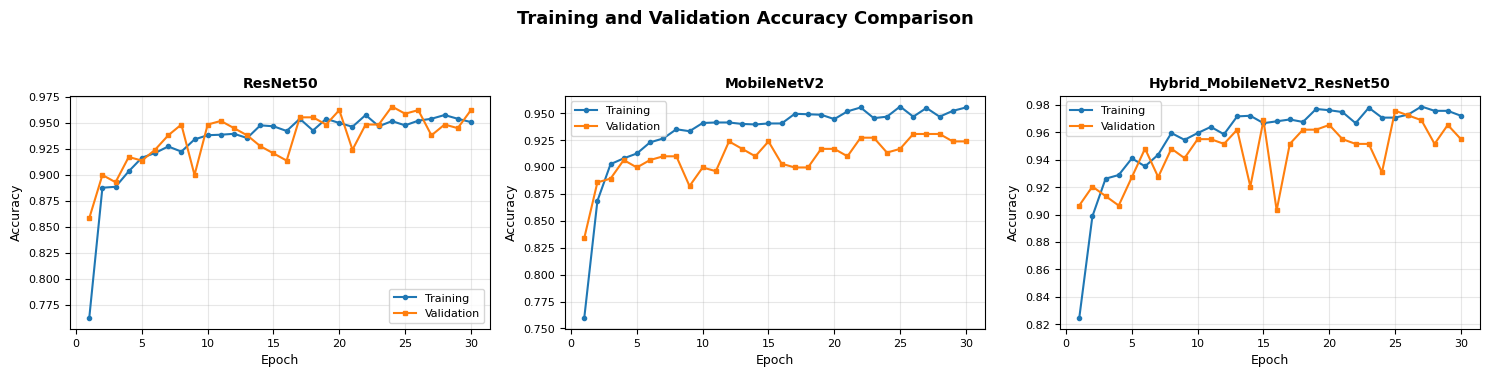

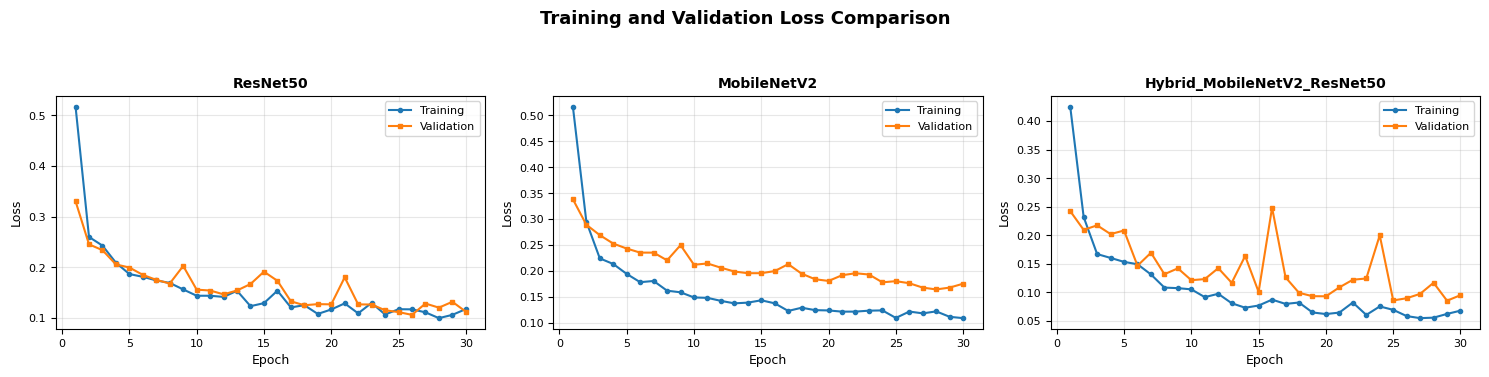

Training histories and comparison graphs saved successfully!


In [27]:
# Save the training history of every model
for model_name, history in trained_histories.items():
    history_data = {key: [float(v) for v in values] for key, values in history.history.items()}
    with (HISTORIES_DIR / f"{model_name}_history.json").open("w") as file:
        json.dump(history_data, file, indent=2)

def plot_history(metric, ylabel, title, filename):
    # One subplot per model, training vs validation
    fig, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(5 * len(MODEL_NAMES), 3.8), squeeze=False)
    for ax, model_name in zip(axes[0], MODEL_NAMES):
        history = trained_histories[model_name].history
        epochs_seen = range(1, len(history[metric]) + 1)
        ax.plot(epochs_seen, history[metric], marker="o", markersize=3, linewidth=1.5, label="Training")
        ax.plot(epochs_seen, history[f"val_{metric}"], marker="s", markersize=3, linewidth=1.5, label="Validation")
        ax.set_title(model_name, fontsize=10, fontweight="bold")
        ax.set_xlabel("Epoch", fontsize=9)
        ax.set_ylabel(ylabel, fontsize=9)
        ax.tick_params(labelsize=8)
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
    fig.suptitle(title, fontsize=13, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    fig.savefig(GRAPHS_DIR / filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

plot_history("accuracy", "Accuracy", "Training and Validation Accuracy Comparison", "all_models_accuracy_comparison.png")
plot_history("loss", "Loss", "Training and Validation Loss Comparison", "all_models_loss_comparison.png")
print("Training histories and comparison graphs saved successfully!")

## 8. Evaluation on the validation and test sets
The same metric functions are applied to every model.

In [28]:
def collect_labels(dataset):
    return np.concatenate([labels.numpy() for _, labels in dataset]).astype(int)

y_test = collect_labels(test_ds)
y_val = collect_labels(val_ds)
test_one_hot = np.eye(NUM_CLASSES)[y_test]

for split_name, labels in (("validation", y_val), ("test", y_test)):
    present_classes = set(np.unique(labels).tolist())
    if present_classes != set(class_indices.tolist()):
        raise ValueError(
            f"The {split_name} split must contain every class for macro ROC-AUC; "
            f"found class indices {sorted(present_classes)}"
        )

def calculate_specificity(y_true, y_pred):
    matrix = confusion_matrix(y_true, y_pred, labels=class_indices)
    per_class_specificity = []
    for class_index in class_indices:
        true_positive = matrix[class_index, class_index]
        false_negative = matrix[class_index, :].sum() - true_positive
        false_positive = matrix[:, class_index].sum() - true_positive
        true_negative = matrix.sum() - true_positive - false_negative - false_positive
        denominator = true_negative + false_positive
        per_class_specificity.append(true_negative / denominator if denominator else np.nan)
    return float(np.nanmean(per_class_specificity))

def macro_roc_auc(y_true, probabilities):
    if NUM_CLASSES == 2:
        return float(roc_auc_score(y_true, probabilities[:, 1]))
    return float(roc_auc_score(y_true, probabilities, labels=class_indices,
                               multi_class="ovr", average="macro"))

def calculate_metrics(y_true, probabilities):
    predictions = np.argmax(probabilities, axis=1)
    return {
        "Accuracy (%)": accuracy_score(y_true, predictions) * 100,
        "Precision - Macro (%)": precision_score(y_true, predictions, average="macro", zero_division=0) * 100,
        "Recall / Sensitivity - Macro (%)": recall_score(y_true, predictions, average="macro", zero_division=0) * 100,
        "Specificity - Macro (%)": calculate_specificity(y_true, predictions) * 100,
        "F1-score - Macro (%)": f1_score(y_true, predictions, average="macro", zero_division=0) * 100,
        "ROC-AUC - Macro": macro_roc_auc(y_true, probabilities),
        "Average Precision - Macro": average_precision_score(
            np.eye(NUM_CLASSES)[y_true], probabilities, average="macro"
        ),
    }

test_probabilities = {}
val_probabilities = {}
comparison_rows = []
per_class_reports = {}

for model_name in MODEL_NAMES:
    model = trained_models[model_name]
    print("Evaluating:", model_name)
    val_probabilities[model_name] = model.predict(val_ds, verbose=0)
    test_probabilities[model_name] = model.predict(test_ds, verbose=0)

    val_predictions = np.argmax(val_probabilities[model_name], axis=1)
    test_predictions = np.argmax(test_probabilities[model_name], axis=1)
    val_macro_f1 = f1_score(y_val, val_predictions, average="macro", zero_division=0) * 100
    test_metrics = calculate_metrics(y_test, test_probabilities[model_name])

    weights_path = MODELS_DIR / f"{model_name}_best.weights.h5"
    test_metrics.update({
        "Model": model_name,
        "Validation Macro F1 (%)": val_macro_f1,
        "Training Time (minutes)": training_seconds[model_name] / 60,
        "Model Weights (MB)": weights_path.stat().st_size / (1024 ** 2),
    })
    comparison_rows.append(test_metrics)

    per_class_reports[model_name] = pd.DataFrame(
        classification_report(y_test, test_predictions, labels=class_indices,
                              target_names=class_names, output_dict=True, zero_division=0)
    ).T
    per_class_reports[model_name].to_csv(METRICS_DIR / f"{model_name}_per_class_metrics.csv")

    prediction_table = pd.DataFrame({
        "sample_index": np.arange(len(y_test)),
        "file_path": test_file_paths,
        "true_label": [class_names[i] for i in y_test],
        "predicted_label": [class_names[i] for i in test_predictions],
        "confidence": np.max(test_probabilities[model_name], axis=1),
    })
    for class_index, class_name in enumerate(class_names):
        prediction_table[f"probability_{class_name}"] = test_probabilities[model_name][:, class_index]
    prediction_table.to_csv(PREDICTIONS_DIR / f"{model_name}_test_predictions.csv", index=False)

# Models stay in the fixed order ResNet50 -> MobileNetV2 -> Hybrid
comparison_df = pd.DataFrame(comparison_rows).set_index("Model").loc[MODEL_NAMES]
display(comparison_df.round(3))
comparison_df.to_csv(METRICS_DIR / "model_comparison.csv")

Evaluating: ResNet50
Evaluating: MobileNetV2
Evaluating: Hybrid_MobileNetV2_ResNet50


,Accuracy (%),Precision - Macro (%),Recall / Sensitivity - Macro (%),Specificity - Macro (%),F1-score - Macro (%),ROC-AUC - Macro,Average Precision - Macro,Validation Macro F1 (%),Training Time (minutes),Model Weights (MB)
Model,,,,,,,,,,
ResNet50,95.205,95.237,95.237,97.203,95.237,0.988,0.979,96.228,6.830,90.519
MobileNetV2,92.466,92.669,92.256,95.507,92.456,0.980,0.961,93.168,2.615,9.073
Hybrid_MobileNetV2_ResNet50,95.205,95.065,95.495,97.301,95.273,0.991,0.986,96.610,8.505,99.580


## 9. Performance comparison: metrics, confusion matrices, ROC and Precision-Recall curves

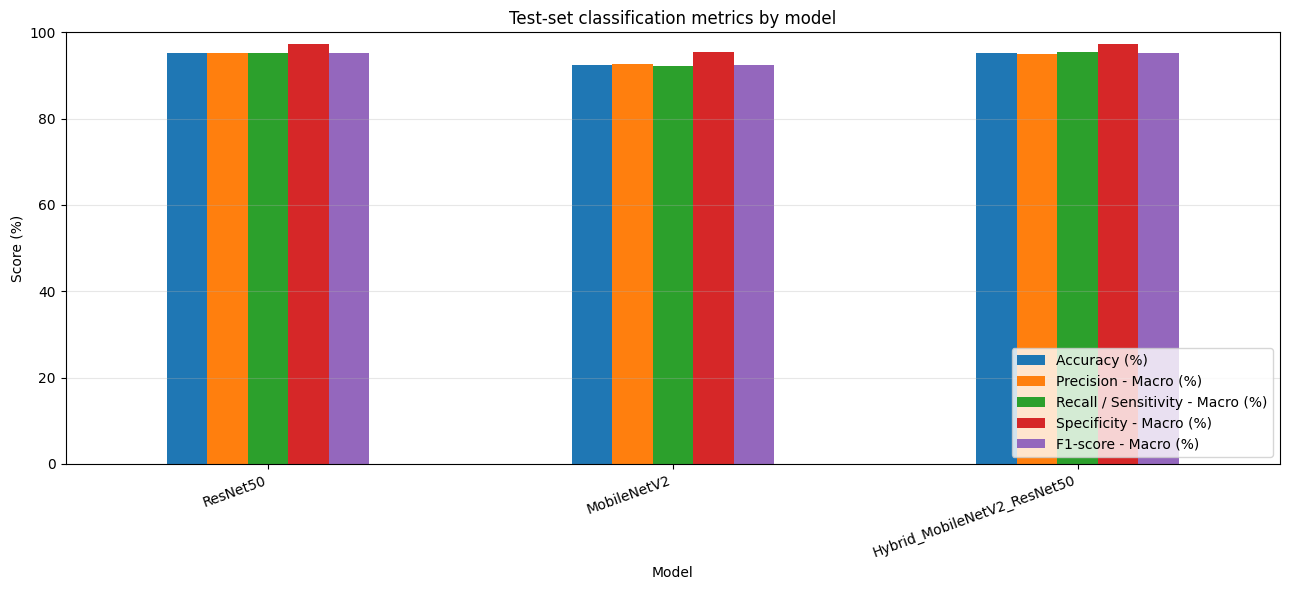


ResNet50: test-set per-class precision, recall, and F1


,precision,recall,f1-score,support
Benign,0.901,0.901,0.901,71.0
Malignant,0.956,0.956,0.956,158.0
Normal,1.000,1.000,1.000,63.0



MobileNetV2: test-set per-class precision, recall, and F1


,precision,recall,f1-score,support
Benign,0.855,0.831,0.843,71.0
Malignant,0.925,0.937,0.931,158.0
Normal,1.000,1.000,1.000,63.0



Hybrid_MobileNetV2_ResNet50: test-set per-class precision, recall, and F1


,precision,recall,f1-score,support
Benign,0.890,0.915,0.903,71.0
Malignant,0.962,0.949,0.955,158.0
Normal,1.000,1.000,1.000,63.0


In [29]:
metric_columns = [
    "Accuracy (%)",
    "Precision - Macro (%)",
    "Recall / Sensitivity - Macro (%)",
    "Specificity - Macro (%)",
    "F1-score - Macro (%)",
]
ax = comparison_df[metric_columns].plot(kind="bar", figsize=(13, 6), ylim=(0, 100))
ax.set_title("Test-set classification metrics by model")
ax.set_xlabel("Model")
ax.set_ylabel("Score (%)")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(GRAPHS_DIR / "model_metric_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

for model_name, report in per_class_reports.items():
    print(f"\n{model_name}: test-set per-class precision, recall, and F1")
    display(report.loc[class_names, ["precision", "recall", "f1-score", "support"]].round(3))

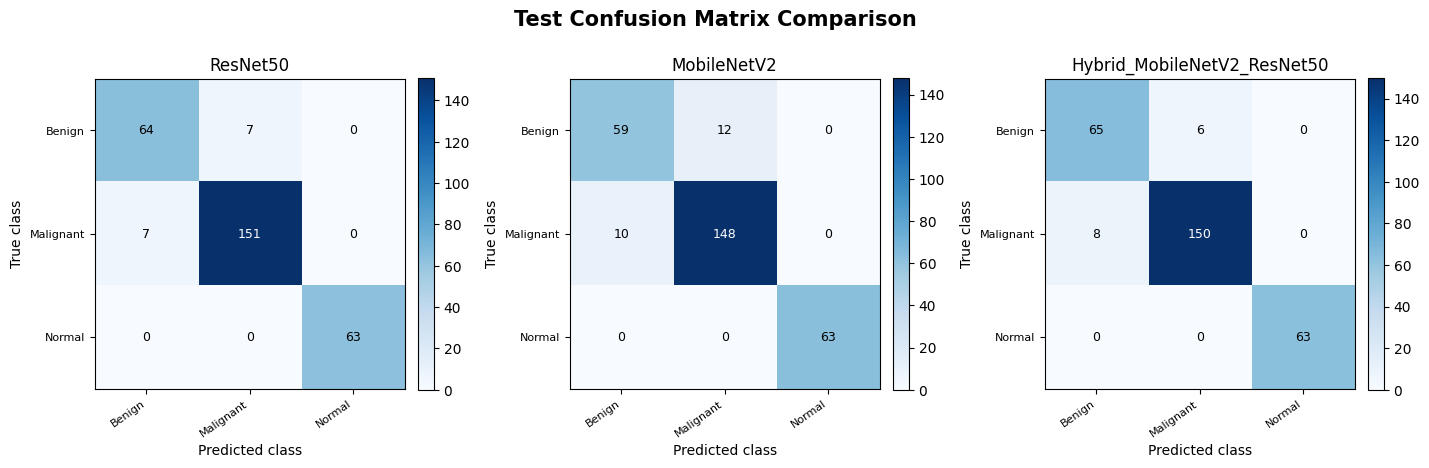

In [30]:
# Confusion matrices (test set), one per model
n_models = len(MODEL_NAMES)
fig, axes = plt.subplots(1, n_models, figsize=(4.8 * n_models, 4.5), squeeze=False)

for ax, model_name in zip(axes[0], MODEL_NAMES):
    predictions = np.argmax(test_probabilities[model_name], axis=1)
    matrix = confusion_matrix(y_test, predictions, labels=class_indices)

    image = ax.imshow(matrix, cmap="Blues")
    ax.set(title=model_name, xlabel="Predicted class", ylabel="True class",
           xticks=class_indices, yticks=class_indices,
           xticklabels=class_names, yticklabels=class_names)
    ax.tick_params(axis="both", labelsize=8)
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right")

    # Write the counts inside the cells
    threshold = matrix.max() / 2 if matrix.size else 0
    for r in range(NUM_CLASSES):
        for c in range(NUM_CLASSES):
            ax.text(c, r, str(matrix[r, c]), ha="center", va="center", fontsize=9,
                    color="white" if matrix[r, c] > threshold else "black")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

fig.suptitle("Test Confusion Matrix Comparison", fontsize=15, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(GRAPHS_DIR / "all_models_confusion_matrix_comparison.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

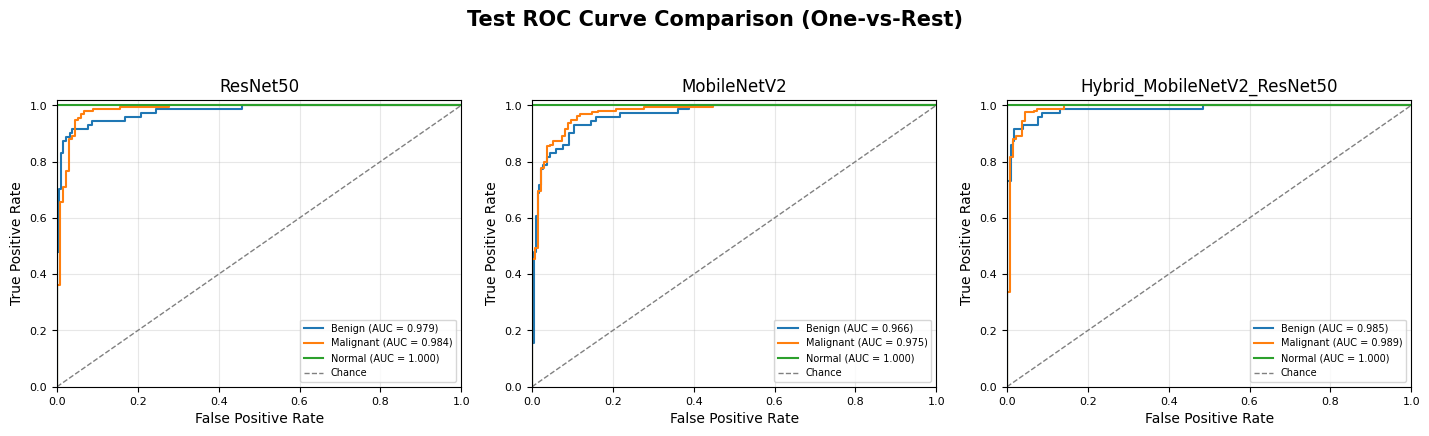

In [31]:
# ROC curves (one-vs-rest, test set), one per model
fig, axes = plt.subplots(1, n_models, figsize=(4.8 * n_models, 4.4), squeeze=False)

for ax, model_name in zip(axes[0], MODEL_NAMES):
    probabilities = test_probabilities[model_name]
    for class_index, class_name in enumerate(class_names):
        fpr, tpr, _ = roc_curve(test_one_hot[:, class_index], probabilities[:, class_index])
        class_auc = roc_auc_score(test_one_hot[:, class_index], probabilities[:, class_index])
        ax.plot(fpr, tpr, linewidth=1.5, label=f"{class_name} (AUC = {class_auc:.3f})")

    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1, label="Chance")
    ax.set(title=model_name, xlabel="False Positive Rate", ylabel="True Positive Rate",
           xlim=(0, 1), ylim=(0, 1.02))
    ax.tick_params(labelsize=8)
    ax.legend(loc="lower right", fontsize=7)
    ax.grid(alpha=0.3)

fig.suptitle("Test ROC Curve Comparison (One-vs-Rest)", fontsize=15, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(GRAPHS_DIR / "all_models_roc_curve_comparison.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

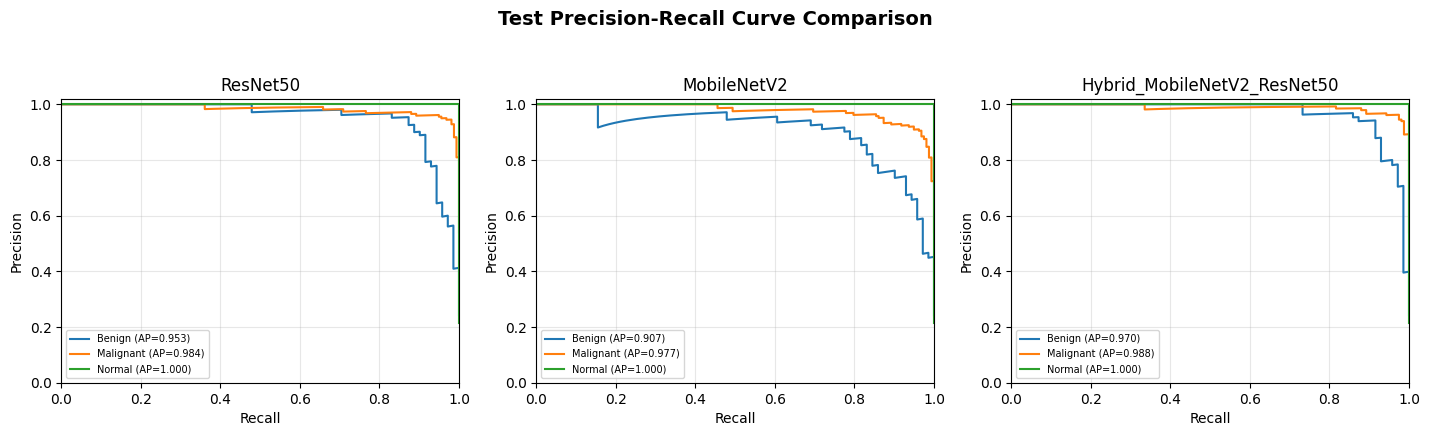

In [32]:
# Precision-Recall curves (test set), one per model
fig, axes = plt.subplots(1, n_models, figsize=(4.8 * n_models, 4.4), squeeze=False)

for ax, model_name in zip(axes[0], MODEL_NAMES):
    probabilities = test_probabilities[model_name]
    for class_index, class_name in enumerate(class_names):
        precision, recall, _ = precision_recall_curve(test_one_hot[:, class_index], probabilities[:, class_index])
        ap = average_precision_score(test_one_hot[:, class_index], probabilities[:, class_index])
        ax.plot(recall, precision, label=f"{class_name} (AP={ap:.3f})")

    ax.set(title=model_name, xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(loc="best", fontsize=7)
    ax.grid(alpha=0.3)

fig.suptitle("Test Precision-Recall Curve Comparison", fontsize=14, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(GRAPHS_DIR / "all_models_precision_recall_comparison.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

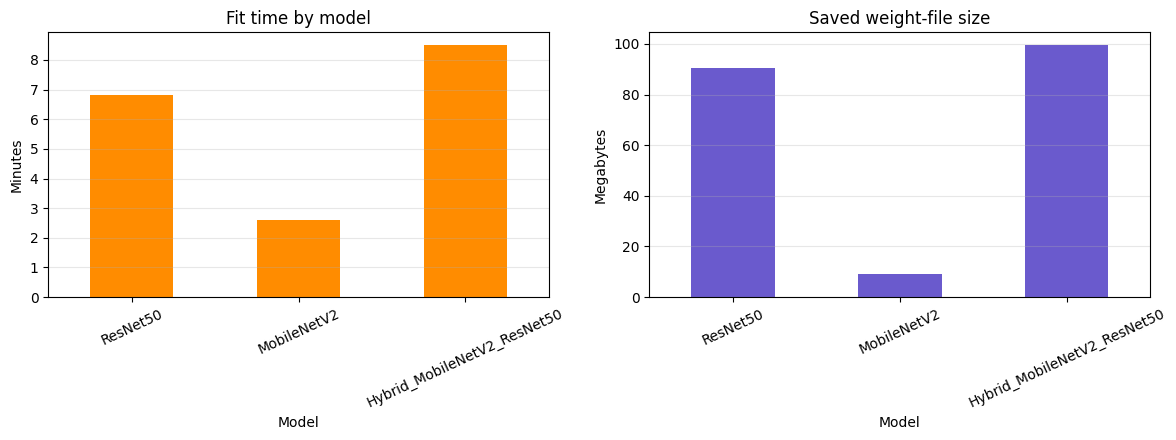

In [33]:
# Training time and saved weight-file size
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
comparison_df["Training Time (minutes)"].plot(kind="bar", ax=axes[0], color="darkorange")
axes[0].set(title="Fit time by model", xlabel="Model", ylabel="Minutes")
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(axis="y", alpha=0.3)

comparison_df["Model Weights (MB)"].plot(kind="bar", ax=axes[1], color="slateblue")
axes[1].set(title="Saved weight-file size", xlabel="Model", ylabel="Megabytes")
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(GRAPHS_DIR / "training_time_and_model_size.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

## 10. Explainability: Grad-CAM and Grad-CAM++

**How it works (kept simple):**
- The heatmap is computed from the last convolutional feature map of each frozen backbone (7×7 for both ResNet50 and MobileNetV2).
- The explained class is the class the model **predicted** for that image, using its pre-softmax score (logit), so the gradients do not vanish when the softmax saturates.
- **Grad-CAM:** channel weights = mean gradient of each channel.
- **Grad-CAM++:** channel weights = gradients weighted by pixel-wise alpha coefficients (better for multiple/small regions).
- **Hybrid model:** it has two backbones, so a heatmap is computed for each backbone and the two (each normalised to 0–1) are averaged.
- **Same images for every model:** the test images are picked once, with a fixed seed, and passed to all three models.

The forward pass is re-run branch by branch (preprocessing → backbone → GAP → concat → final Dense) so gradients can be taken with respect to the backbone feature maps.
A built-in check confirms this re-run reproduces the real model's predictions exactly.

In [34]:
XAI_IMAGES_PER_CLASS = 2          # number of test images explained per class
XAI_METHODS = ["Grad-CAM", "Grad-CAM++"]
HEATMAP_ALPHA = 0.4               # heatmap opacity in the overlay

# Name prefix Keras gives each backbone layer (used to find the backbone inside a model)
BACKBONE_PREFIX = {"ResNet50": "resnet50", "MobileNetV2": "mobilenetv2"}

def find_backbone(model, branch):
    matches = [layer for layer in model.layers
               if isinstance(layer, tf.keras.Model) and layer.name.lower().startswith(BACKBONE_PREFIX[branch])]
    if len(matches) != 1:
        raise ValueError(f"Expected exactly one {branch} backbone in {model.name}, found {len(matches)}")
    return matches[0]

def forward_with_feature_maps(model, images, branch_names):
    # Re-runs the model so we can return the backbone feature maps together with the class logits.
    feature_maps, pooled = [], []
    for branch in branch_names:
        x = model.get_layer(f"{branch}_preprocessing")(images)
        feature_map = find_backbone(model, branch)(x, training=False)
        feature_maps.append(feature_map)
        pooled.append(tf.reduce_mean(feature_map, axis=[1, 2]))      # global average pooling

    features = tf.concat(pooled, axis=-1)                            # (concatenation is a no-op for one branch)
    kernel, bias = model.get_layer("class_probabilities").get_weights()
    logits = tf.matmul(features, tf.constant(kernel)) + tf.constant(bias)   # dropout is inactive at inference
    return feature_maps, logits

def grad_cam(feature_map, grads):
    # Weights = average gradient per channel
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    return tf.nn.relu(tf.reduce_sum(weights * feature_map, axis=-1))[0]

def grad_cam_plus_plus(feature_map, grads):
    # Weights = gradients (positive part) scaled by alpha coefficients
    grads_2, grads_3 = grads ** 2, grads ** 3
    feature_sum = tf.reduce_sum(feature_map, axis=(1, 2), keepdims=True)
    denominator = 2.0 * grads_2 + feature_sum * grads_3
    denominator = tf.where(denominator != 0.0, denominator, tf.ones_like(denominator))  # avoid divide-by-zero
    alpha = grads_2 / denominator
    weights = tf.reduce_sum(alpha * tf.nn.relu(grads), axis=(1, 2), keepdims=True)
    return tf.nn.relu(tf.reduce_sum(weights * feature_map, axis=-1))[0]

def normalise_and_resize(cam):
    # Scale to 0-1 and upsample the small feature-map heatmap to the input image size
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return tf.image.resize(cam[..., None], IMG_SIZE)[..., 0].numpy()

def explain_image(model, branch_names, image):
    # Returns (predicted class, confidence, {method: heatmap}) for one image (H, W, 3) in 0-255 range.
    images = tf.convert_to_tensor(image[None], dtype=tf.float32)
    with tf.GradientTape() as tape:
        tape.watch(images)                                            # so gradients reach the frozen backbones
        feature_maps, logits = forward_with_feature_maps(model, images, branch_names)
        predicted_class = int(tf.argmax(logits[0]).numpy())
        score = logits[0, predicted_class]
    grads = tape.gradient(score, feature_maps)
    confidence = float(tf.nn.softmax(logits)[0, predicted_class].numpy())

    heatmaps = {}
    for method, cam_function in (("Grad-CAM", grad_cam), ("Grad-CAM++", grad_cam_plus_plus)):
        # One heatmap per backbone; averaged when there is more than one (Hybrid model)
        branch_maps = [normalise_and_resize(cam_function(f, g)) for f, g in zip(feature_maps, grads)]
        heatmap = np.mean(branch_maps, axis=0)
        heatmaps[method] = heatmap / (heatmap.max() + 1e-8)
    return predicted_class, confidence, heatmaps

def load_image(path):
    # Same loading / resizing as image_dataset_from_directory (RGB, bilinear resize, 0-255 floats)
    image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    return tf.image.resize(image, IMG_SIZE).numpy().astype("float32")

def overlay_heatmap(image, heatmap, alpha=HEATMAP_ALPHA):
    colored = plt.get_cmap("jet")(heatmap)[..., :3]
    return np.clip((1 - alpha) * image / 255.0 + alpha * colored, 0, 1)

print("XAI helper functions defined.")

XAI helper functions defined.


### 10.1 Select the test images (once, shared by all models) and compute the heatmaps

In [38]:
# Pick the same images for every model: XAI_IMAGES_PER_CLASS random test images per class (fixed seed).
rng = np.random.default_rng(SEED)
xai_indices = []
for class_index in class_indices:
    candidates = np.where(y_test == class_index)[0]
    chosen = rng.choice(candidates, size=min(XAI_IMAGES_PER_CLASS, len(candidates)), replace=False)
    xai_indices.extend(sorted(int(i) for i in chosen))

xai_paths = [test_file_paths[i] for i in xai_indices]
xai_images = np.stack([load_image(path) for path in xai_paths])
xai_true = y_test[xai_indices]
print(f"Selected {len(xai_indices)} test images (identical for all models):")
for i, path in zip(xai_indices, xai_paths):
    print(f"  test index {i:>5} | {class_names[y_test[i]]:<12} | {Path(path).name}")

# Safety check: our re-run of the model must give the same probabilities as the real model.
for model_name in MODEL_NAMES:
    model = trained_models[model_name]
    _, logits = forward_with_feature_maps(model, tf.constant(xai_images), get_branches(model_name))
    expected = model(tf.constant(xai_images), training=False).numpy()
    assert np.allclose(tf.nn.softmax(logits).numpy(), expected, atol=1e-3), \
        f"XAI forward pass does not match the real model for {model_name}"
print("XAI forward pass matches the trained models.")

# Compute predictions + heatmaps for every model on the same images
xai_results = {model_name: [] for model_name in MODEL_NAMES}
for model_name in MODEL_NAMES:
    for image in xai_images:
        pred, conf, heatmaps = explain_image(trained_models[model_name], get_branches(model_name), image)
        xai_results[model_name].append({"pred": pred, "conf": conf, **heatmaps})

    # Soft check: predictions should agree with the test-set evaluation above
    eval_preds = np.argmax(test_probabilities[model_name][xai_indices], axis=1)
    xai_preds = np.array([r["pred"] for r in xai_results[model_name]])
    print(f"{model_name}: XAI predictions agree with test-set predictions on {np.mean(eval_preds == xai_preds) * 100:.0f}% of the selected images")

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
Selected 6 test images (identical for all models):
  test index     6 | Benign       | Benign (134).JPG
  test index    54 | Benign       | Benign (389).JPG
  test index   139 | Malignant    | Malignant (472).JPG
  test index   228 | Malignant    | Malignant (987).JPG
  test index   234 | Normal       | Normal case (128).jpg
  test index   272 | Normal       | Normal case (357).jpg
XAI forward pass matches the trained models.
ResNet50: XAI predictions agree with test-set predictions on 100% of the selected images
MobileNetV2: XAI predictions agree with test-set predictions on 100% of the selected images
Hybrid_MobileNetV2_ResNet50: XAI predictions agree with test-set predictions on 100% of the selected images


### 10.2 Side-by-side comparison: predictions + Grad-CAM + Grad-CAM++ for all models
Title colour: **green** = correct prediction, **red** = wrong prediction. Warmer overlay colours = more influence on the predicted class.

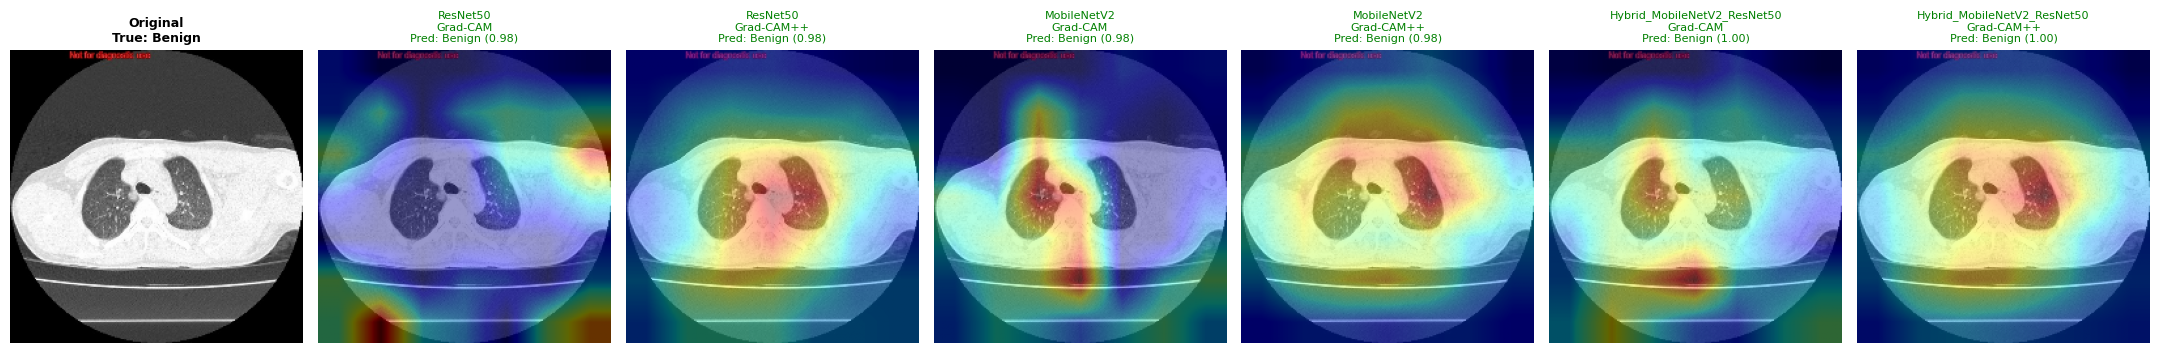

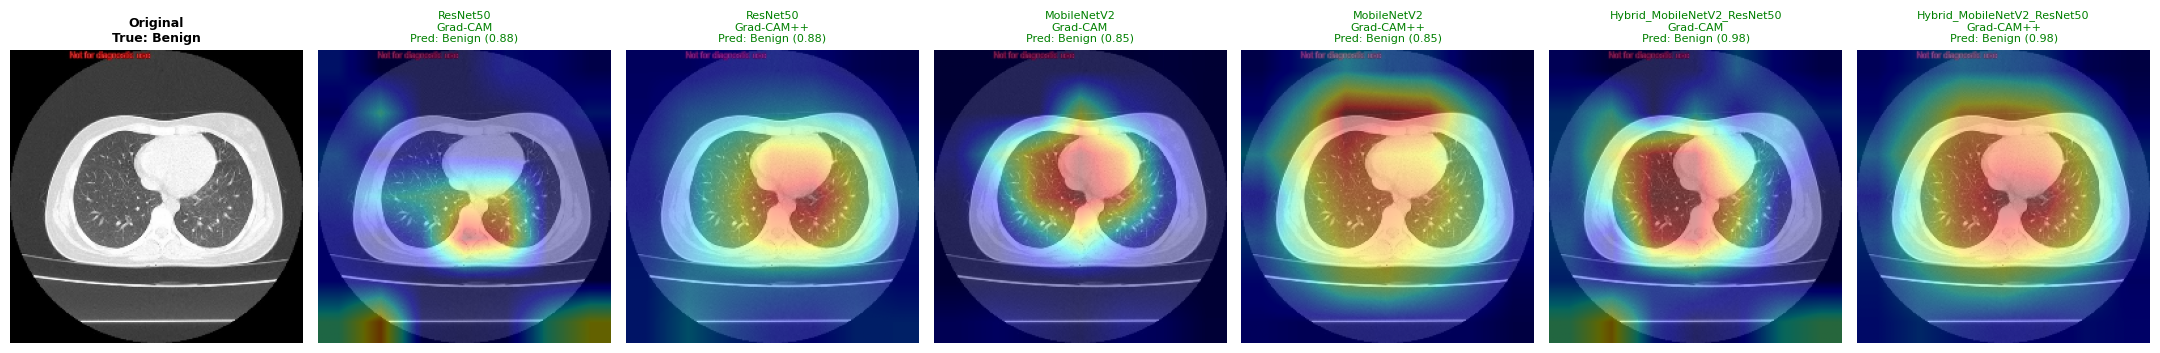

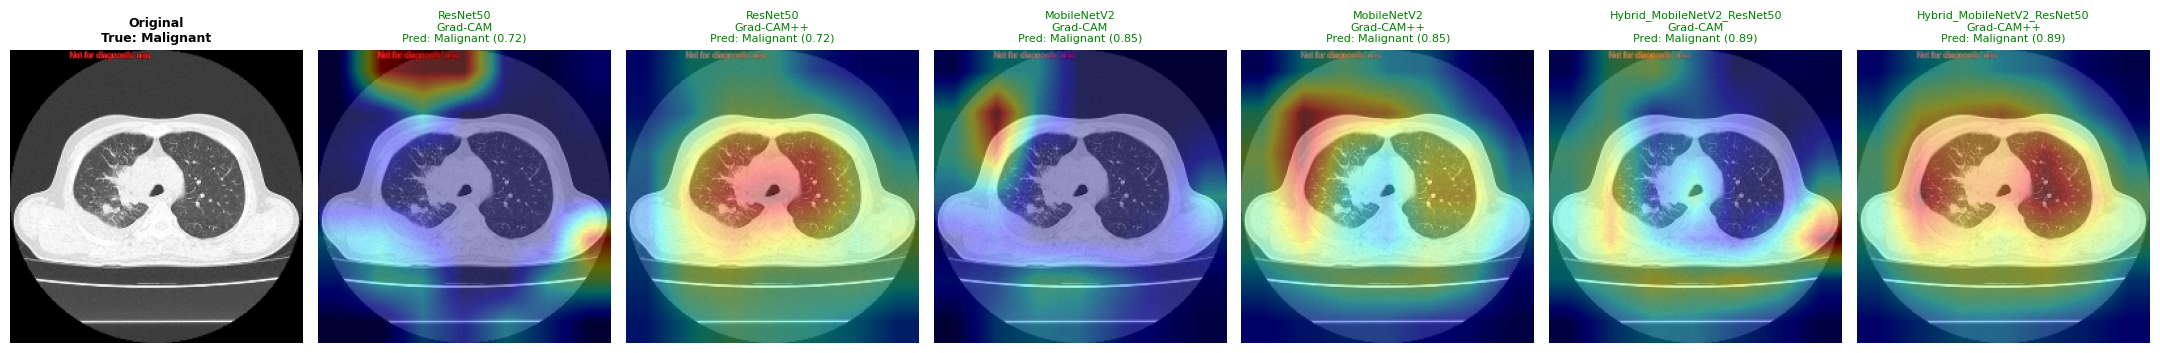

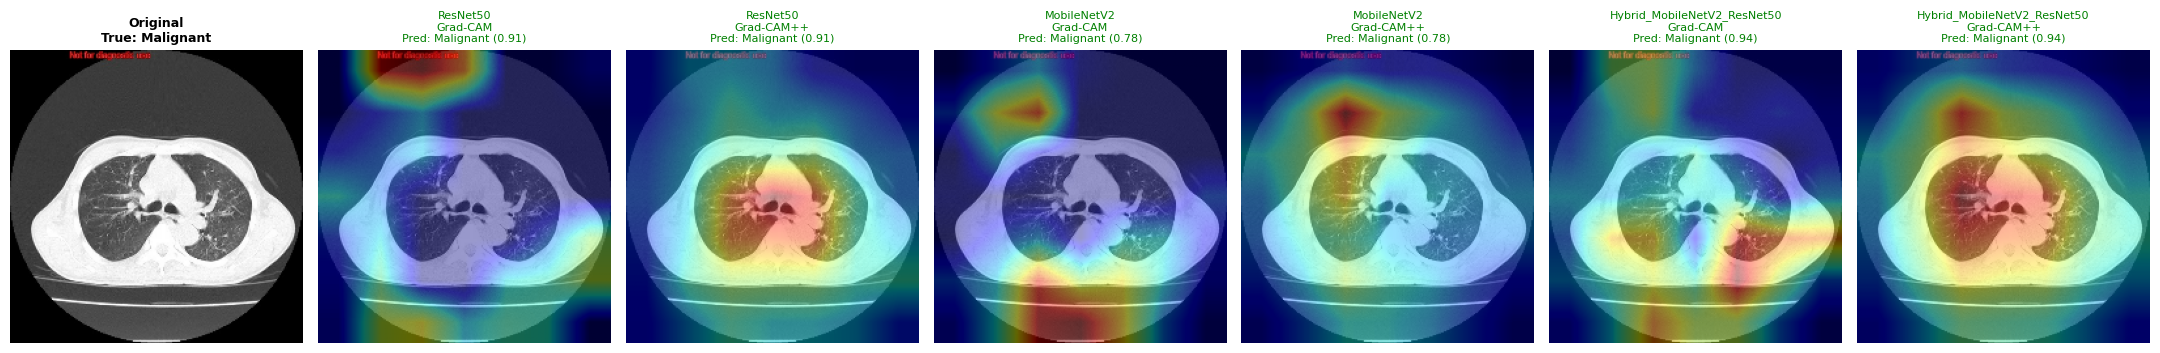

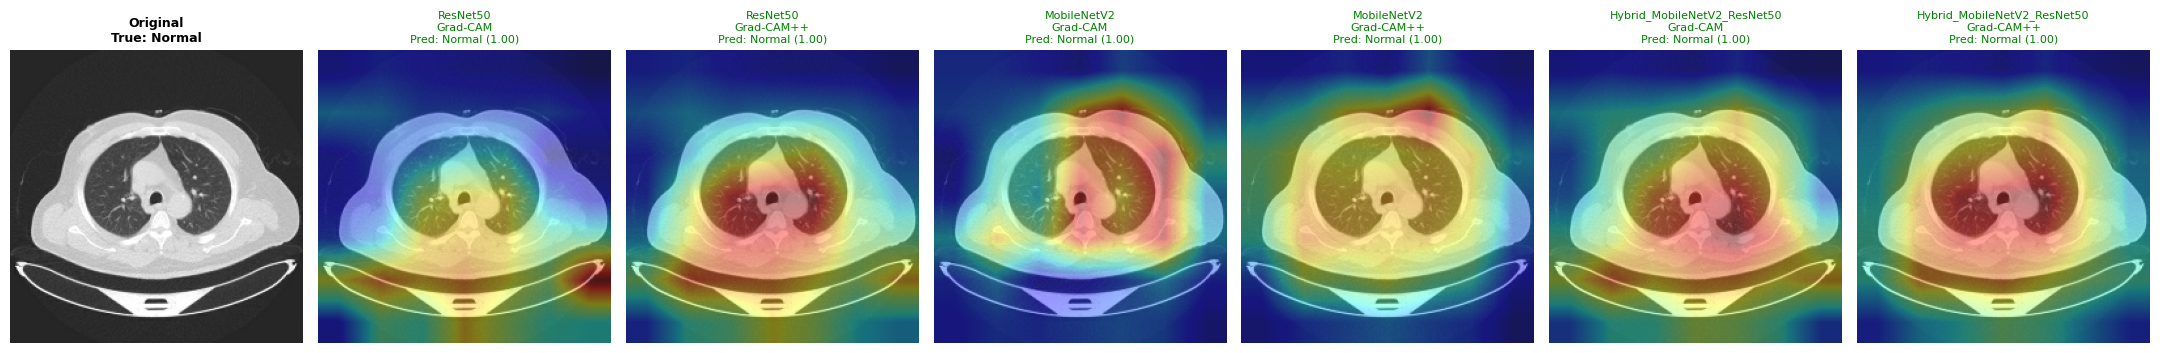

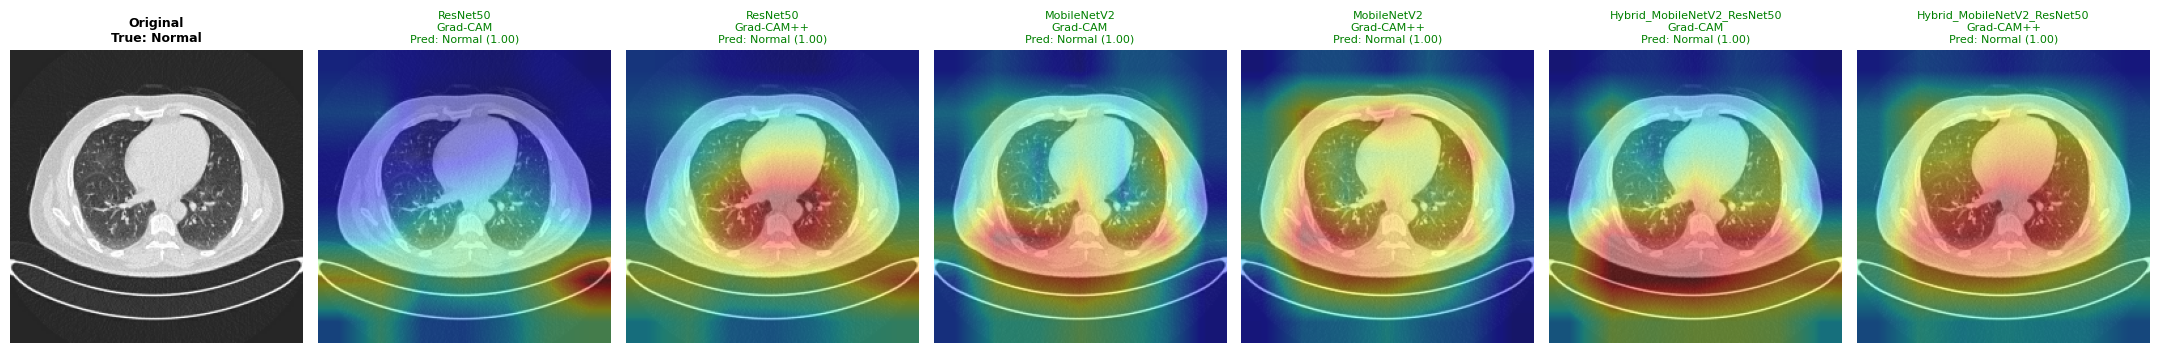

,test_index,file,true_label,ResNet50,MobileNetV2,Hybrid_MobileNetV2_ResNet50
0,6,Benign (134).JPG,Benign,Benign (0.98),Benign (0.98),Benign (1.00)
1,54,Benign (389).JPG,Benign,Benign (0.88),Benign (0.85),Benign (0.98)
2,139,Malignant (472).JPG,Malignant,Malignant (0.72),Malignant (0.85),Malignant (0.89)
3,228,Malignant (987).JPG,Malignant,Malignant (0.91),Malignant (0.78),Malignant (0.94)
4,234,Normal case (128).jpg,Normal,Normal (1.00),Normal (1.00),Normal (1.00)
5,272,Normal case (357).jpg,Normal,Normal (1.00),Normal (1.00),Normal (1.00)


XAI figures saved in: /kaggle/working/Lung_Cancer_Classification_Results/run_20261127_111117/xai


In [39]:
n_cols = 1 + len(MODEL_NAMES) * len(XAI_METHODS)

for i, path in enumerate(xai_paths):
    fig, axes = plt.subplots(1, n_cols, figsize=(3.1 * n_cols, 3.9))

    # Column 0: the original image
    axes[0].imshow(xai_images[i].astype("uint8"))
    axes[0].set_title(f"Original\nTrue: {class_names[xai_true[i]]}", fontsize=9, fontweight="bold")

    # Then, for each model: Grad-CAM and Grad-CAM++ side by side
    col = 1
    for model_name in MODEL_NAMES:
        result = xai_results[model_name][i]
        color = "green" if result["pred"] == xai_true[i] else "red"
        for method in XAI_METHODS:
            axes[col].imshow(overlay_heatmap(xai_images[i], result[method]))
            axes[col].set_title(
                f"{model_name}\n{method}\nPred: {class_names[result['pred']]} ({result['conf']:.2f})",
                fontsize=8, color=color)
            col += 1

    for ax in axes:
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(XAI_DIR / f"xai_test_{xai_indices[i]:05d}_{class_names[xai_true[i]]}.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# Prediction summary for the explained images (same images for all models)
rows = []
for i, path in enumerate(xai_paths):
    row = {"test_index": xai_indices[i], "file": Path(path).name, "true_label": class_names[xai_true[i]]}
    for model_name in MODEL_NAMES:
        result = xai_results[model_name][i]
        row[model_name] = f"{class_names[result['pred']]} ({result['conf']:.2f})"
    rows.append(row)
xai_summary_df = pd.DataFrame(rows)
display(xai_summary_df)
xai_summary_df.to_csv(XAI_DIR / "xai_selected_images_predictions.csv", index=False)
print("XAI figures saved in:", XAI_DIR)

## 11. Save experiment configuration and final summary

In [40]:
experiment_config = {
    "run_id": RUN_ID,
    "seed": SEED,
    "dataset_root": str(DATASET_ROOT),
    "split_directories": {"train": str(TRAIN_DIR), "validation": str(VAL_DIR), "test": str(TEST_DIR)},
    "class_names_in_label_order": class_names,
    "sample_counts_by_class": split_counts,
    "input_size": list(IMG_SIZE),
    "batch_size": BATCH_SIZE,
    "epochs_max": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "optimizer": "Adam",
    "loss": "sparse_categorical_crossentropy",
    "dropout_rate": DROPOUT_RATE,
    "early_stopping": {"monitor": "val_loss", "patience": EARLY_STOPPING_PATIENCE},
    "pretrained_weights": "ImageNet",
    "backbone_trainable": False,
    "data_augmentation": "No online augmentation; the pre-augmented dataset on disk is used",
    "models": MODEL_NAMES,
    "hybrid_configs": {name: list(branches) for name, branches in HYBRID_CONFIGS.items()},
    "xai": {
        "methods": XAI_METHODS,
        "explained_class": "predicted class (pre-softmax score)",
        "target_layer": "last conv feature map of each backbone (Hybrid: average of both backbones)",
        "images_per_class": XAI_IMAGES_PER_CLASS,
        "selected_test_indices": xai_indices,
        "selected_files": xai_paths,
    },
    "test_set_used_for_selection": False,
    "tensorflow_version": tf.__version__,
    "python_version": platform.python_version(),
    "numpy_version": np.__version__,
    "scikit_learn_version": sklearn.__version__,
    "tensorflow_build_info": build_info,
    "visible_gpu_devices": [device.name for device in gpu_devices],
    "determinism_note": (
        "Seeds and deterministic TensorFlow operations are enabled where supported. "
        "Exact reproducibility across hardware and software versions is not guaranteed."
    ),
}

with (CONFIG_DIR / "experiment_config.json").open("w") as file:
    json.dump(experiment_config, file, indent=2, default=str)

comparison_df.to_json(METRICS_DIR / "model_comparison.json", orient="table", indent=2)
print("Experiment configuration and comparison results saved.")
print("Run folder:", RUN_DIR)

Experiment configuration and comparison results saved.
Run folder: /kaggle/working/Lung_Cancer_Classification_Results/run_20261127_111117


In [41]:
# Final summary (the best model is chosen by VALIDATION macro F1, not by the test set)
best_model_name = comparison_df["Validation Macro F1 (%)"].idxmax()
best_row = comparison_df.loc[best_model_name]
print("Model selected by validation macro F1:", best_model_name)
print(f"Validation macro F1: {best_row['Validation Macro F1 (%)']:.2f}%")
print(f"Test accuracy: {best_row['Accuracy (%)']:.2f}%")
print(f"Test macro precision: {best_row['Precision - Macro (%)']:.2f}%")
print(f"Test macro recall/sensitivity: {best_row['Recall / Sensitivity - Macro (%)']:.2f}%")
print(f"Test macro specificity: {best_row['Specificity - Macro (%)']:.2f}%")
print(f"Test macro F1: {best_row['F1-score - Macro (%)']:.2f}%")
print(f"Test macro ROC-AUC: {best_row['ROC-AUC - Macro']:.3f}")

history = trained_histories[best_model_name].history
training_validation_gap = history["accuracy"][-1] - history["val_accuracy"][-1]
print(f"\nFinal-epoch training minus validation accuracy: {training_validation_gap:.3f}")
if training_validation_gap > 0.10 and history["val_loss"][-1] > min(history["val_loss"]):
    print("The final epochs may show overfitting; inspect the learning curves.")
elif history["accuracy"][-1] < 0.70 and history["val_accuracy"][-1] < 0.70:
    print("Both final accuracies are relatively low; inspect for possible underfitting or data issues.")
else:
    print("No simple overfitting/underfitting rule is conclusive; inspect the learning curves and class metrics.")

print("\nAll run artifacts are under:", RUN_DIR)

Model selected by validation macro F1: Hybrid_MobileNetV2_ResNet50
Validation macro F1: 96.61%
Test accuracy: 95.21%
Test macro precision: 95.06%
Test macro recall/sensitivity: 95.50%
Test macro specificity: 97.30%
Test macro F1: 95.27%
Test macro ROC-AUC: 0.991

Final-epoch training minus validation accuracy: 0.017
No simple overfitting/underfitting rule is conclusive; inspect the learning curves and class metrics.

All run artifacts are under: /kaggle/working/Lung_Cancer_Classification_Results/run_20261127_111117
